# 03 从循环到 NumPy 与线性代数

## 1 四个点放进一张表

这一课处理四个点：$(0,0)$、$(0,2)$、$(4,0)$、$(4,2)$，它们组成一个矩形。要把矩形移到原点附近，或者为每个点计算几种加权输出，上一课的循环已经能完成。NumPy 让我们用数组表达同样的计算，省去逐个元素写循环的部分。

每行保存一个点，每列保存一个坐标。将这张表记为 $X\in\mathbb R^{n\times d}$，n=4 是样本数，d=2 是坐标数。以后把一行换成图像像素或某次测量的多个特征，这种排列仍然能用。

`np.array(..., dtype=float)` 将嵌套列表转成浮点数组，外层列表给行，内层给列。`shape` 是各轴长度，`ndim` 是轴数。本课用 np 作为 NumPy 的别名，用 Matplotlib 画出计算后的点。

In [1]:
from support import ROOT, check, show, style

In [2]:
import numpy as np
import matplotlib.pyplot as plt
style()
X = np.array([[0., 0.], [0., 2.], [4., 0.], [4., 2.]], dtype=float)
print(X)
print("shape:", X.shape, "ndim:", X.ndim, "dtype:", X.dtype)

[[0. 0.]
 [0. 2.]
 [4. 0.]
 [4. 2.]]
shape: (4, 2) ndim: 2 dtype: float64


## 2 行、列与切片

打印的表有四行两列，对应 `(4,2)`。取编号 2 的点时，希望拿到它的两个坐标；取纵坐标时，则希望拿到四个点各自的一个数。

`X[i,r]` 用 i 选行、r 选列，下标仍从 0 开始。`X[i]` 得到一维的 `(d,)`，`X[i:i+1]` 则保留成二维的一行 `(1,d)`。`X[:,r]` 取一列，返回一维数组 `(n,)`。这些结果的数值可能相同，轴的组织方式却会影响它们接下来怎样参与运算。

In [3]:
print("一行：", X[2], X[2].shape)
print("二维的一行：", X[2:3], X[2:3].shape)
print("纵坐标列：", X[:, 1], X[:, 1].shape)
print("指定元素：", X[3, 1])

一行： [4. 0.] (2,)
二维的一行： [[4. 0.]] (1, 2)
纵坐标列： [0. 2. 0. 2.] (4,)
指定元素： 2.0


### 练习 np01：预先判断形状

取出最后一行、前两行和全部横坐标。再填写前两行的形状。

In [4]:
ex_np01_X = np.array([[0., 0.], [0., 2.], [4., 0.], [4., 2.]])
ex_np01_last = None   # TODO
ex_np01_first2 = None  # TODO
ex_np01_x = None      # TODO
ex_np01_shape = None  # TODO

In [5]:
# 填写上一格后，运行检查。
check("最后一行", ex_np01_last, [4., 2.])
check("前两行", ex_np01_first2, [[0., 0.], [0., 2.]])
check("横坐标", ex_np01_x, [0., 0., 4., 4.])
check("前两行形状", ex_np01_shape, (2, 2))

待填写：最后一行
待填写：前两行
待填写：横坐标
待填写：前两行形状


<details>
<summary>提示</summary>

最后一行 [-1]；前两行 [:2]；横坐标 [:, 0]。形状通过取出结果的 .shape 获取。

</details>

<details>
<summary>参考答案</summary>

```python
ex_np01_last = ex_np01_X[-1]
ex_np01_first2 = ex_np01_X[:2]
ex_np01_x = ex_np01_X[:, 0]
ex_np01_shape = ex_np01_first2.shape
```

</details>

## 3 先用循环计算每列均值

矩形的中心在 $(2,1)$。用程序求它时，每个坐标应分别平均：横坐标 $[0,0,4,4]$ 的均值为 2，纵坐标 $[0,2,0,2]$ 的均值为 1。

循环固定一列 r，把这一列的四项加起来，再除以样本数 n。`np.zeros(d)` 建立 d 个 0，给两个坐标的结果留位置。这里每个下标都有明确工作：i 选择哪一个点，r 选择这个点的哪一个坐标。

In [6]:
mean_loop = np.zeros(X.shape[1])
for r in range(X.shape[1]):
    total = 0.
    for i in range(X.shape[0]):
        total += X[i, r]
    mean_loop[r] = total / X.shape[0]
print(mean_loop)

[2. 1.]


刚才的循环最后保留了两个坐标，四个样本被平均掉了。NumPy 用 `mean(axis=0)` 表达这件事：沿样本轴做均值，留下每列一个结果。相应地，`sum(axis=1)` 把每个点的坐标相加，留下四个结果。

axis 指定被合并的轴。在这张表里，轴 0 是样本，轴 1 是坐标。`keepdims=True` 把被合并的轴保留为长度 1，于是均值可以排成 `(1,2)` 的一行。下一格既比较数值，也打印这种排列差别。

In [7]:
mean_vector = X.mean(axis=0)
mean_row = X.mean(axis=0, keepdims=True)
row_sums = X.sum(axis=1)
print(mean_vector, mean_vector.shape)
print(mean_row, mean_row.shape)
print(row_sums, row_sums.shape)
check("循环与数组均值一致", mean_vector, mean_loop)

[2. 1.] (2,)
[[2. 1.]] (1, 2)
[0. 2. 4. 6.] (4,)
通过：循环与数组均值一致


### 练习 np02：沿正确的轴求和

对一个 3×2 数组，计算每列的和、每行的和，以及保留二维形状的每行和。

In [8]:
ex_np02_X = np.array([[1., 2.], [3., 4.], [5., 6.]])
ex_np02_columns = None  # TODO
ex_np02_rows = None     # TODO
ex_np02_column_shape = None  # TODO：(3, 1)

In [9]:
# 填写上一格后，运行检查。
check("每列的和", ex_np02_columns, [9., 12.])
check("每行的和", ex_np02_rows, [3., 7., 11.])
check("保留列形状", ex_np02_column_shape, [[3.], [7.], [11.]])

待填写：每列的和
待填写：每行的和
待填写：保留列形状


<details>
<summary>提示</summary>

每列的和用 axis=0；每行的和用 axis=1；保留成一列时加 keepdims=True。

</details>

<details>
<summary>参考答案</summary>

```python
ex_np02_columns = ex_np02_X.sum(axis=0)
ex_np02_rows = ex_np02_X.sum(axis=1)
ex_np02_column_shape = ex_np02_X.sum(axis=1, keepdims=True)
```

</details>

## 4 广播前，先写逐元素相减

找到中心以后，把每个点都减去 $(2,1)$，矩形就移到了原点周围。对第一个点，这一步给出 $(-2,-1)$；对最后一个点，给出 $(2,1)$。

循环仍按样本 i、坐标 r 计算 `X[i,r] - mean[r]`。同一个均值坐标会在每一行重复使用，这正是接下来广播要表达的重复关系。

In [10]:
centered_loop = np.zeros(X.shape)
for i in range(X.shape[0]):
    for r in range(X.shape[1]):
        centered_loop[i, r] = X[i, r] - mean_vector[r]
print(centered_loop)

[[-2. -1.]
 [-2.  1.]
 [ 2. -1.]
 [ 2.  1.]]


`X - mean_vector` 将同一组两坐标与每行配对。形状 `(4,2)` 和 `(2,)` 从右边对齐，两个坐标分别相减，后者的同一组数被用于四行。这种按形状配对运算的方式叫广播。

从右边检查各轴，对应长度相同，或其中一个长度为 1，就能配合。结果仍是四个二维点，中心化后的列均值变为 `[0,0]`。广播省掉了显式循环，计算出来的结果数组仍要占用内存。

In [11]:
centered_vector = X - mean_vector
print(centered_vector)
print("中心化后的列均值：", centered_vector.mean(axis=0))
check("相减的两种实现", centered_vector, centered_loop)

[[-2. -1.]
 [-2.  1.]
 [ 2. -1.]
 [ 2.  1.]]
中心化后的列均值： [0. 0.]
通过：相减的两种实现


### 练习 np03：给每一行加同一个向量

每个样本的第一个坐标加 10，第二个坐标减 1。直接用广播完成。

In [12]:
ex_np03_X = np.array([[0., 0.], [0., 2.], [4., 0.]])
ex_np03_shift = np.array([10., -1.])
ex_np03_shifted = None  # TODO

In [13]:
# 填写上一格后，运行检查。
check("平移后的三个点", ex_np03_shifted, [[10., -1.], [10., 1.], [14., -1.]])

待填写：平移后的三个点


<details>
<summary>提示</summary>

两个输入形状为 (3,2)、(2,)，直接相加。

</details>

<details>
<summary>参考答案</summary>

```python
ex_np03_shifted = ex_np03_X + ex_np03_shift
```

</details>

## 5 同时为所有点与所有中心配对

每行减同一个向量已经会了。现在给出两个参考点 $(0,0)$、$(4,2)$，希望知道每个样本到两者各有多远。一个样本需要两个结果，所以距离表应有四行两列。

用 C 保存 K 个参考点，形状为 `(K,d)`。第 i 个样本到第 j 个参考点的平方距离记作 $D^2_{ij}=\sum_r(X_{ir}-C_{jr})^2$：坐标相减、平方、相加。循环遍历每一对 i、j，`np.sum` 负责最后的坐标求和。

In [14]:
C = np.array([[0., 0.], [4., 2.]])
D2_loop = np.zeros((len(X), len(C)))
for i in range(len(X)):
    for j in range(len(C)):
        D2_loop[i, j] = np.sum((X[i] - C[j]) ** 2)
print(D2_loop)

[[ 0. 20.]
 [ 4. 16.]
 [16.  4.]
 [20.  0.]]


这次重复发生在“样本与参考点的所有配对”上。给它们分别留一个可配对的轴：`X[:,None,:]` 成为 `(n,1,d)`，`C[None,:,:]` 成为 `(1,K,d)`。索引里的 None 插入长度为 1 的新轴，相减后便得到 `(n,K,d)`。

三个轴依次是样本、参考点、坐标。例如 `diff[1]` 有两行，表示点 $(0,2)$ 到两个参考点的坐标差：`[0,2]` 与 `[-4,0]`。沿坐标轴 2 求平方和，得到 4、16；所有样本同样处理，就还原了循环算出的 `(n,K)` 距离表。

In [15]:
X_expanded, C_expanded = X[:, None, :], C[None, :, :]
diff = X_expanded - C_expanded
D2 = (diff ** 2).sum(axis=2)
print("加轴后：", X_expanded.shape, C_expanded.shape)
print("差值：", diff.shape, "距离表：", D2.shape)
print("点 1 对全部中心的坐标差：\n", diff[1])
check("广播与循环距离一致", D2, D2_loop)

加轴后： (4, 1, 2) (1, 2, 2)
差值： (4, 2, 2) 距离表： (4, 2)
点 1 对全部中心的坐标差：
 [[ 0.  2.]
 [-4.  0.]]
通过：广播与循环距离一致


图里每行对应一个样本，每列对应一个参考点。第 0 行的 0、20 表示第一个点就在参考点 0 上，到参考点 1 的平方距离为 20。沿着这些具体位置读图，三维的坐标差最终被压成了二维的配对结果。

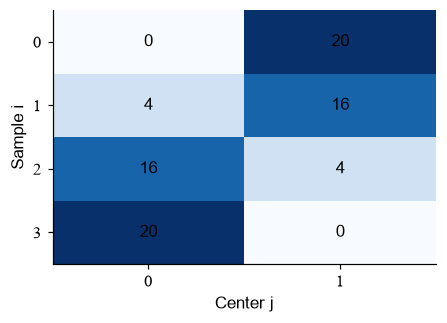

In [16]:
fig, ax = plt.subplots(figsize=(4.5, 3))
ax.imshow(D2, cmap="Blues", aspect="auto")
for i in range(len(X)):
    for j in range(len(C)):
        ax.text(j, i, f"{D2[i,j]:.0f}", ha="center", va="center", color="black")
ax.set(xticks=[0, 1], yticks=range(len(X)), xlabel="Center j", ylabel="Sample i")
show(fig)

### 练习 np04：亲手完成三维到二维

给定两个点、两个中心，使用广播计算平方距离表。不要把样本轴或中心轴加起来。

In [17]:
ex_np04_X = np.array([[0., 0.], [2., 1.]])
ex_np04_C = np.array([[0., 1.], [3., 1.]])
ex_np04_diff = None  # TODO：(2,2,2)
ex_np04_D2 = None    # TODO：(2,2)

In [18]:
# 填写上一格后，运行检查。
check("配对的坐标差", ex_np04_diff, [[[0., -1.], [-3., -1.]], [[2., 0.], [-1., 0.]]])
check("配对的平方距离", ex_np04_D2, [[1., 10.], [4., 1.]])

待填写：配对的坐标差
待填写：配对的平方距离


<details>
<summary>提示</summary>

先 X[:,None,:] - C[None,:,:]，平方后 sum(axis=2)。

</details>

<details>
<summary>参考答案</summary>

```python
ex_np04_diff = ex_np04_X[:, None, :] - ex_np04_C[None, :, :]
ex_np04_D2 = (ex_np04_diff ** 2).sum(axis=2)
```

</details>

## 6 取最小值的编号，再按编号取值

距离表有了，每个点可以选择更近的参考点。我们要的是列编号，才能知道选中了谁。`np.argmin(一行)` 返回最小值所在的列，`np.argmin(D2,axis=1)` 将这一步同时用于四行。

结果 `[0,0,1,1]` 把矩形左边两点与右边两点分开。还可以按这些编号取出各自选中的距离：`np.arange(n)` 提供行编号，`D2[行编号数组,列编号数组]` 按相同位置配对索引，得到 `[0,4,4,0]`。

In [19]:
nearest_loop = []
for i in range(len(X)):
    nearest_loop.append(np.argmin(D2[i]))
nearest = np.argmin(D2, axis=1)
chosen_distances = D2[np.arange(len(X)), nearest]
print(nearest, chosen_distances)
check("逐行与整表分配一致", nearest, nearest_loop)

[0 0 1 1] [0. 4. 4. 0.]
通过：逐行与整表分配一致


`nearest==0` 给出 `[True,True,False,False]`。把这个条件放进 X 的方括号，就取得左边两点；这种布尔索引保留条件成立的行。整数数组索引则按给定编号取行，`X[[3,0]]` 会把最后一个点放在前面，第一个点放在后面。

In [20]:
print("布尔条件：", nearest == 0)
print("属于中心 0 的点：\n", X[nearest == 0])
print("按编号重排两行：\n", X[[3, 0]])

布尔条件： [ True  True False False]
属于中心 0 的点：
 [[0. 0.]
 [0. 2.]]
按编号重排两行：
 [[4. 2.]
 [0. 0.]]


### 练习 np05：分配、筛选、取对应数值

从给定距离表逐行选最近列，取每行选中的值，再保留分到中心 1 的样本行编号。

In [21]:
ex_np05_D2 = np.array([[1., 8.], [9., 2.], [4., 3.]])
ex_np05_nearest = None  # TODO
ex_np05_chosen = None   # TODO
ex_np05_ids = None      # TODO

In [22]:
# 填写上一格后，运行检查。
check("最近中心", ex_np05_nearest, [0, 1, 1])
check("对应距离", ex_np05_chosen, [1., 2., 3.])
check("中心 1 的样本行", ex_np05_ids, [1, 2])

待填写：最近中心
待填写：对应距离
待填写：中心 1 的样本行


<details>
<summary>提示</summary>

取编号用 argmin(axis=1)；取对应值用两列配对索引；行编号数组按 nearest==1 筛选。

</details>

<details>
<summary>参考答案</summary>

```python
ex_np05_nearest = np.argmin(ex_np05_D2, axis=1)
ex_np05_chosen = ex_np05_D2[np.arange(3), ex_np05_nearest]
ex_np05_ids = np.arange(3)[ex_np05_nearest == 1]
```

</details>

## 7 内积：逐坐标相乘再相加

距离将坐标差合成了一个数，另一种常见的合成方式是加权求和。例如输入 $(4,2)$，权重 $(2,-0.5)$，输出是 $4\times2+2\times(-0.5)=7$。第一项向上贡献 8，第二项向下贡献 1。

两个 d 维向量 x、w 的内积定义为 $x^\top w=\sum_{r=0}^{d-1}x_rw_r$，上标 $\top$ 表示转置。两个一维数组的 `x @ w` 就得到这个标量；循环仍然是逐坐标相乘、累加。

In [23]:
x = np.array([4., 2.])
w = np.array([2., -0.5])
dot_loop = 0.
for r in range(len(x)):
    dot_loop += x[r] * w[r]
print("循环：", dot_loop, "逐元素后求和：", np.sum(x*w), "内积：", x @ w)

循环： 7.0 逐元素后求和： 7.0 内积： 7.0


### 练习 np06：算一个神经元的加权和

输入三个坐标、三个权重和一个偏置，计算 z = x @ w + b。先手算乘积再求和。

In [24]:
ex_np06_x = np.array([1., 2., -1.])
ex_np06_w = np.array([0.5, -0.2, 0.3])
ex_np06_b = 0.1
ex_np06_z = None  # TODO

In [25]:
# 填写上一格后，运行检查。
check("激活前加权和", ex_np06_z, -0.1)

待填写：激活前加权和


<details>
<summary>提示</summary>

乘积分别是 0.5、−0.4、−0.3，再加偏置 0.1。

</details>

<details>
<summary>参考答案</summary>

```python
ex_np06_z = ex_np06_x @ ex_np06_w + ex_np06_b
```

</details>

## 8 矩阵乘法：同时计算多个输出

一个输入可以交给几组权重，产生几个不同的输出。将每组权重放在 W 的一列里，形状为 `(d,m)`，m 就是输出数。$W_{rj}$ 表示输入坐标 r 对输出 j 的权重，$Y_{ij}=\sum_r X_{ir}W_{rj}$。

下一格选择的权重让输出 0 保留横坐标，输出 1 等于“半个横坐标加纵坐标”。四个点各算两项，每一项内部都做一个内积，因此循环中出现样本 i、输出 j、输入坐标 r 三个下标。

In [26]:
W = np.array([[1., 0.5], [0., 1.]])
Y_loop = np.zeros((len(X), W.shape[1]))
for i in range(len(X)):
    for j in range(W.shape[1]):
        for r in range(X.shape[1]):
            Y_loop[i, j] += X[i, r] * W[r, j]
print(Y_loop)

[[0. 0.]
 [0. 2.]
 [4. 2.]
 [4. 4.]]


矩阵乘法 `X @ W` 把这三个循环压在同一个运算里。形状是 `(n,d) @ (d,m) → (n,m)`，中间的 d 代表被相乘求和的输入坐标。`*` 做逐元素相乘，`@` 则按这个求和规则组合行与列。

如果每个输出再加一个固定量，把它们放进 `(m,)` 的偏置 b，`X @ W + b` 就会给每行加同一组偏置。本例加 `[-1,0.2]` 后，最后一个点 $(4,2)$ 变成 $(3,4.2)$，可以直接核对图中的位置。

In [27]:
Y = X @ W
b = np.array([-1., 0.2])
Y_with_bias = Y + b
print("X、W、Y：", X.shape, W.shape, Y.shape)
print("加上偏置：\n", Y_with_bias)
check("矩阵乘法与三层循环一致", Y, Y_loop)

X、W、Y： (4, 2) (2, 2) (4, 2)
加上偏置：
 [[-1.   0.2]
 [-1.   2.2]
 [ 3.   2.2]
 [ 3.   4.2]]
通过：矩阵乘法与三层循环一致


### 练习 np07：独立做一批线性变换

两行样本、三个输入坐标、两个输出。计算整批输出并填写输出形状。

In [28]:
ex_np07_X = np.array([[1., 0., 2.], [0., 1., 1.]])
ex_np07_W = np.array([[1., 0.], [0., 2.], [-1., 1.]])
ex_np07_b = np.array([0.5, -0.5])
ex_np07_Y = None      # TODO
ex_np07_shape = None  # TODO

In [29]:
# 填写上一格后，运行检查。
check("线性变换输出", ex_np07_Y, [[-0.5, 1.5], [-0.5, 2.5]])
check("输出形状", ex_np07_shape, (2, 2))

待填写：线性变换输出
待填写：输出形状


<details>
<summary>提示</summary>

(2,3) @ (3,2) 得到 (2,2)，再把 (2,) 偏置加给每一行。

</details>

<details>
<summary>参考答案</summary>

```python
ex_np07_Y = ex_np07_X @ ex_np07_W + ex_np07_b
ex_np07_shape = ex_np07_Y.shape
```

</details>

## 9 转置与形状决定可计算的连接

刚才内积中的输入坐标沿着求和方向排好，矩阵乘法才表达了所需计算。需要交换输入与输出所占的轴时，可以对二维数组用 `.T` 转置：`(d,m)` 变成 `(m,d)`。下一课反向传播会用到这样的方向变化。

`.reshape(...)` 按元素顺序重新排列形状，元素总数保持相同。它与转置各做自己的事。下面把一个 2×3 数组分别转成 3×2，观察同一个数最终落在哪一格。

In [30]:
shape_demo = np.array([[1., 2., 3.], [4., 5., 6.]])
print("原数组：\n", shape_demo)
print("转置：\n", shape_demo.T)
print("重新排成 3×2：\n", shape_demo.reshape(3, 2))

原数组：
 [[1. 2. 3.]
 [4. 5. 6.]]
转置：
 [[1. 4.]
 [2. 5.]
 [3. 6.]]
重新排成 3×2：
 [[1. 2.]
 [3. 4.]
 [5. 6.]]


转置的第一行是 `[1,4]`，它来自原来的第一列；reshape 的第一行是 `[1,2]`，它来自按行读出的前两个数。形状相同，元素关系已经不同。仅看输出尺寸，还不足以判断一段张量代码是否表达了正确计算。

## 10 保存副本，再修改当前状态

下一课要比较参数更新前后的结果，需要留住一份旧值。这里有个容易直接看见的差别：NumPy 的基本切片常与原数组共享存储，改切片里的数，原来的表也会跟着改变。

下一格把同一块区域分别作为切片和 `.copy()` 保存。将切片的第一项改成 99 后，原数组也出现 99，副本却仍保存 1。训练历史中的“旧参数”就需要这样的独立副本。

In [31]:
copy_source = np.array([[1., 2.], [3., 4.], [5., 6.]])
shared_slice = copy_source[:2]
saved_copy = copy_source[:2].copy()
shared_slice[0, 0] = 99.
print("原数组：\n", copy_source)
print("保存副本：\n", saved_copy)

原数组：
 [[99.  2.]
 [ 3.  4.]
 [ 5.  6.]]
保存副本：
 [[1. 2.]
 [3. 4.]]


## 11 把矩阵计算画成几何变换

四个点已经经过 `X @ W + b`：横坐标整体减 1，新的纵坐标混入半个旧横坐标，再加 0.2。原来的矩形因此倾斜并平移。

左右两图保留相同的样本编号，可以把每一行数组与它的几何变化联系起来。绘图里的 `enumerate(points)` 同时提供行编号和这一行的点。

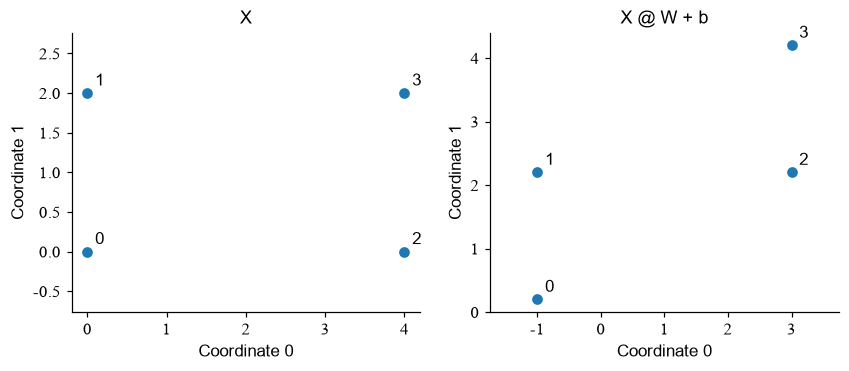

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.3))
for ax, points, title in zip(axes, [X, Y_with_bias], ["X", "X @ W + b"]):
    ax.scatter(points[:, 0], points[:, 1])
    for i, point in enumerate(points):
        ax.annotate(str(i), point, xytext=(5, 5), textcoords="offset points")
    ax.set(xlabel="Coordinate 0", ylabel="Coordinate 1", title=title)
    ax.set_aspect("equal", adjustable="datalim")
show(fig)

## 换成三个输入坐标，计算规则还成立

给出三行样本 `[[1,0,2],[0,1,1],[2,2,0]]`、权重 `[[1,0],[0,2],[-1,1]]`、偏置 `[0.5,-0.5]`。试着独立写出循环版和矩阵版，两份输出应为 `[[-0.5,1.5],[-0.5,2.5],[2.5,3.5]]`。从手算第一行开始，可以确定各列究竟怎样进入两个输出。

用输出第 0 列大于 0 的条件筛选样本，再求这些原始样本的列均值。条件有三个布尔值，对应三行；W 将三个输入变成两个输出。这些形状是计算关系的记录。

表变长以后，两份实现也可以用来做计时实验。`time.perf_counter()` 两次取值相减得到秒数。让样本行重复成较长的表，比较同一组输出的计算时间，并记录表有多大。广播距离里还出现过 `(n,K,d)` 的中间数组，可以按元素数估算它会占多少内存。

## 带着问题读原文

[NumPy 广播规则](https://numpy.org/doc/stable/user/basics.broadcasting.html) 与[《动手学深度学习》线性代数](https://d2l.ai/chapter_preliminaries/linear-algebra.html) 都可以对照这四个点来读。书中的轴、内积、矩阵乘法，分别对应表里的哪一行计算？下一课会给加权输出接上非线性，并追踪误差怎样回到 W 的每一项。